Upload an image for forensic analysis:


Saving Gemini_Generated_Image_se9skose9skose9s.png to Gemini_Generated_Image_se9skose9skose9s.png

========== IMAGE ANALYSIS ==========
File Name: Gemini_Generated_Image_se9skose9skose9s.png
File Size: 9552717 bytes
Image Format: PNG
Dimensions: 2528 x 1684
Color Mode: RGBA

Image Preview:


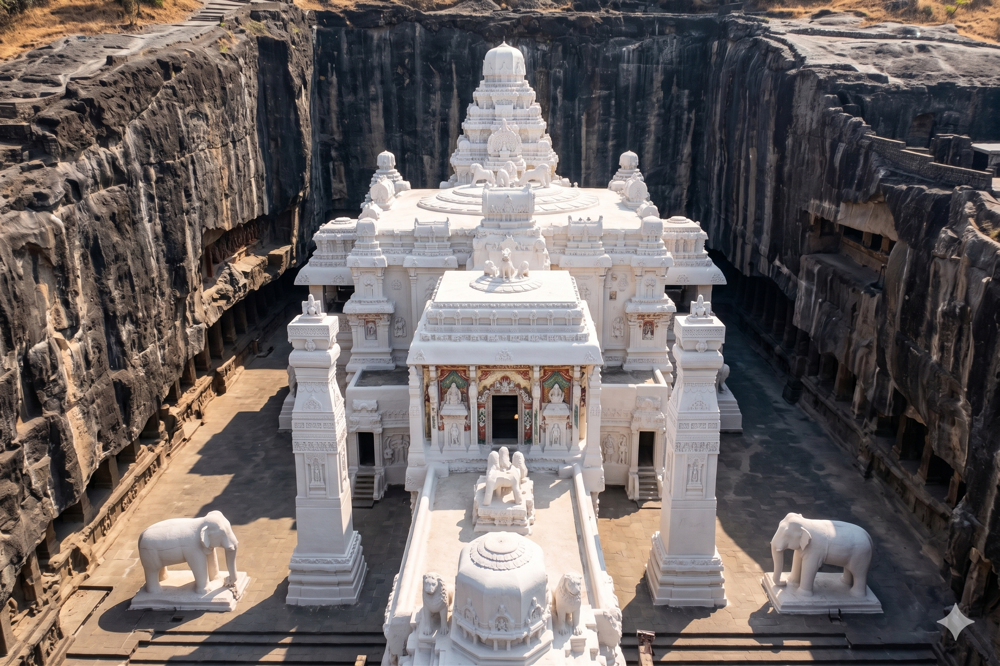


========== EXIF METADATA ==========
No EXIF metadata found.

========== FILE INTEGRITY HASHES ==========
MD5: 24ca9f99d4430d192652422ede68641d
SHA-256: 08edd617b7154c344f8baeaf4d3dcc31a63424e6d29410dbc94bced350039aaf

Report generated successfully!

DIGITAL IMAGE FORENSICS REPORT

File Name: Gemini_Generated_Image_se9skose9skose9s.png
File Size: 9552717 bytes
Image Format: PNG
Dimensions: 2528 x 1684
Color Mode: RGBA

MD5 HASH:
24ca9f99d4430d192652422ede68641d

SHA-256 HASH:
08edd617b7154c344f8baeaf4d3dcc31a63424e6d29410dbc94bced350039aaf

EXIF METADATA:
No EXIF metadata found

Analysis Completed Successfully.



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:

# DIGITAL IMAGE FORENSICS AND METADATA ANALYZER

!pip -q install pillow

import os
import hashlib
from PIL import Image, ExifTags
from google.colab import files
from IPython.display import display

# 1. Upload image
print("Upload an image for forensic analysis:")
uploaded = files.upload()

if uploaded:
    filename = next(iter(uploaded))
    image_data = uploaded[filename]

    # 2. Calculate file properties
    file_size = len(image_data)
    md5_hash = hashlib.md5(image_data).hexdigest()
    sha256_hash = hashlib.sha256(image_data).hexdigest()

    # 3. Open and analyze image
    try:
        from io import BytesIO
        img = Image.open(BytesIO(image_data))

        print("\n========== IMAGE ANALYSIS ==========")

        print("File Name:", filename)
        print("File Size:", file_size, "bytes")
        print("Image Format:", img.format)
        print("Dimensions:", img.width, "x", img.height)
        print("Color Mode:", img.mode)

        # Display image
        print("\nImage Preview:")
        display(img.copy())

        # 4. Extract EXIF metadata
        print("\n========== EXIF METADATA ==========")

        exif_data = img.getexif()
        metadata = []

        if exif_data:
            for tag_id, value in exif_data.items():
                tag = ExifTags.TAGS.get(tag_id, tag_id)
                metadata.append(f"{tag}: {value}")
                print(f"{tag}: {value}")
        else:
            metadata.append("No EXIF metadata found")
            print("No EXIF metadata found.")

        # 5. Display file hashes
        print("\n========== FILE INTEGRITY HASHES ==========")
        print("MD5:", md5_hash)
        print("SHA-256:", sha256_hash)

        # 6. Generate forensic report
        report = f"""
DIGITAL IMAGE FORENSICS REPORT
================================

File Name: {filename}
File Size: {file_size} bytes
Image Format: {img.format}
Dimensions: {img.width} x {img.height}
Color Mode: {img.mode}

MD5 HASH:
{md5_hash}

SHA-256 HASH:
{sha256_hash}

EXIF METADATA:
{chr(10).join(metadata)}

================================
Analysis Completed Successfully.
"""

        # 7. Save report
        report_name = "forensic_analysis_report.txt"

        with open(report_name, "w", encoding="utf-8") as f:
            f.write(report)

        print("\nReport generated successfully!")
        print(report)

        # 8. Download report
        files.download(report_name)

    except Exception as e:
        print("Error: Unable to analyze this image.")
        print("Details:", e)

else:
    print("No image selected.")
